# Trực quan hóa Thực nghiệm Đa Mô hình (Cross-Paradigm Benchmark): SAT vs CP vs MIP cho Bài toán N-Queens

- **Mục tiêu:** Đánh giá và so sánh thời gian thực thi giữa 3 trường phái giải quyết bài toán N-Queens:
  - **SAT Solving (Boolean Satisfiability):** PySAT (**Glucose4** với mã hóa **Commander Variable** AMO).
  - **Constraint Programming (CP):** Google OR-Tools (**CP-SAT**), IBM ILOG CPLEX (**CP Optimizer**).
  - **Mixed Integer Programming (MIP):** **Gurobi Optimizer**, IBM ILOG CPLEX (**MIP**).
- **Không gian khảo sát:** 15 mốc kích thước bàn cờ đồng bộ: $N \in [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]$.
- **Chỉ số đánh giá chính:** Thời gian thực thi (Execution Time tính bằng giây, giới hạn timeout: 120s).


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập phong cách hiển thị biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 13,
    'lines.linewidth': 2,
    'lines.markersize': 7,
})

SOLVER_COLORS = {
    'PySAT (Glucose4)': '#1f77b4',   # Xanh dương (SAT)
    'OR-Tools (CP-SAT)': '#2ca02c',  # Xanh lá (CP)
    'IBM CPLEX (CP)': '#17becf',     # Xanh ngọc (CP)
    'Gurobi (MIP)': '#d62728',       # Đỏ (MIP)
    'IBM CPLEX (MIP)': '#ff7f0e',    # Cam (MIP)
}

SOLVER_LABELS = {
    'PySAT (Glucose4)': 'PySAT (Glucose4)',
    'OR-Tools (CP-SAT)': 'OR-Tools (CP-SAT)',
    'IBM CPLEX (CP)': 'IBM CPLEX (CP)',
    'Gurobi (MIP)': 'Gurobi (MIP)',
    'IBM CPLEX (MIP)': 'IBM CPLEX (MIP)',
}

SOLVER_MARKERS = {
    'PySAT (Glucose4)': 'o',   # Tròn
    'OR-Tools (CP-SAT)': 's',  # Vuông
    'IBM CPLEX (CP)': 'D',     # Kim cương
    'Gurobi (MIP)': '^',       # Tam giác lên
    'IBM CPLEX (MIP)': 'v',    # Tam giác xuống
}

SOLVER_ORDER = [
    'PySAT (Glucose4)',
    'OR-Tools (CP-SAT)',
    'IBM CPLEX (CP)',
    'Gurobi (MIP)',
    'IBM CPLEX (MIP)',
]

print("[✓] Khởi tạo môi trường trực quan hóa Solver thành công!")


[✓] Khởi tạo môi trường trực quan hóa Solver thành công!


In [2]:
# Tải dữ liệu thực nghiệm từ results/data/solver.csv
data_path = Path('../data/solver.csv')
df = pd.read_csv(data_path)

print(f"Tổng số bản ghi thực nghiệm: {len(df)}")
print(f"Danh sách Solver ({len(df['solver'].unique())}): {df['solver'].unique().tolist()}")
print(f"Các trường phái (Families): {df['family'].unique().tolist()}")
print(f"Các giá trị N khảo sát ({len(df['n'].unique())}): {sorted(df['n'].unique().tolist())}")
display(df.head(10))


Tổng số bản ghi thực nghiệm: 75
Danh sách Solver (5): ['PySAT (Glucose4)', 'OR-Tools (CP-SAT)', 'IBM CPLEX (CP)', 'Gurobi (MIP)', 'IBM CPLEX (MIP)']
Các trường phái (Families): ['SAT', 'CP', 'MIP']
Các giá trị N khảo sát (15): [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]


,n,solver,family,variables,constraints,time,sat,status
0,4,PySAT (Glucose4),SAT,26,104,0.000354,True,SAT
1,4,OR-Tools (CP-SAT),CP,4,3,0.006930,True,OPTIMAL
2,4,IBM CPLEX (CP),CP,4,3,0.010402,True,FEASIBLE
3,4,Gurobi (MIP),MIP,16,18,0.001436,True,OPTIMAL
4,4,IBM CPLEX (MIP),MIP,16,18,0.027119,True,OPTIMAL
5,8,PySAT (Glucose4),SAT,146,618,0.000917,True,SAT
6,8,OR-Tools (CP-SAT),CP,8,3,0.004844,True,OPTIMAL
7,8,IBM CPLEX (CP),CP,8,3,0.008597,True,FEASIBLE
8,8,Gurobi (MIP),MIP,64,42,0.000752,True,OPTIMAL
9,8,IBM CPLEX (MIP),MIP,64,42,0.014829,True,OPTIMAL


## 1. Thời gian Thực thi (Execution Time)

### Phân tích Diễn biến Thời gian Thực thi:
- **Miền quy mô nhỏ và vừa ($N \le 343$):** Cả **5 bộ giải đều giải thành công** và hiển thị đầy đủ 5 đường riêng biệt:
  - **IBM CPLEX (CP):** Dẫn đầu tuyệt đối về tốc độ, duy trì thời gian giải dưới $0.04$ giây cho mọi $N \le 343$.
  - **Gurobi (MIP):** Cực kỳ nhanh ở phân khúc này (chỉ $0.36$s tại $N = 343$).
  - **IBM CPLEX (MIP):** Ổn định ở mức $1.94$s tại $N = 343$.
  - **PySAT (Glucose4):** Giải tốt ở mức $2.14$s tại $N = 343$ nhờ mã hóa Commander Variable.
  - **OR-Tools (CP-SAT):** Tăng dần thời gian và đạt $79.70$s tại $N = 343$.
- **Hiện tượng dừng sớm ở quy mô lớn ($N \ge 512$ đến $N = 1000$):**
  - **Google OR-Tools (CP-SAT):** Chạm ngưỡng **Timeout (120 giây)** từ $N = 512, 729, 1000$, do đó đường biểu diễn của OR-Tools kết thúc tại $N = 343$.
  - **Gurobi (MIP):** Giải xuất sắc tới $N = 512$ ($0.838$s) và $N = 729$ ($24.10$s), nhưng chạm ngưỡng **Timeout (120 giây)** tại $N = 1000$, do đó kết thúc tại $N = 729$.
  - **Tại mốc cực đại $N = 1000$:** Có **3 bộ giải** hoàn thành thành công trong thời gian quy định:
    1. **IBM CPLEX (CP):** **0.250 giây** (Quán quân tốc độ).
    2. **PySAT Glucose4:** **18.92 giây** (Hoàn thành bài toán 3 triệu biến nhị phân).
    3. **IBM CPLEX (MIP):** **19.42 giây** (Hoàn thành bài toán 1 triệu biến nhị phân).


solver,PySAT (Glucose4),OR-Tools (CP-SAT),IBM CPLEX (CP),Gurobi (MIP),IBM CPLEX (MIP)
n,,,,,
4,0.000354,0.006930,0.010402,0.001436,0.027119
8,0.000917,0.004844,0.008597,0.000752,0.014829
16,0.017303,0.011416,0.008362,0.007822,0.016948
25,0.172797,0.034547,0.014547,0.002465,0.022689
36,0.039431,0.039437,0.011243,0.015984,0.036020
49,0.815832,0.071425,0.010962,0.008499,0.044594
64,0.065774,0.147537,0.011249,0.011147,0.071553
81,0.280503,0.277318,0.013246,0.017800,0.094604
100,0.175485,0.445412,0.014226,0.030660,0.126954


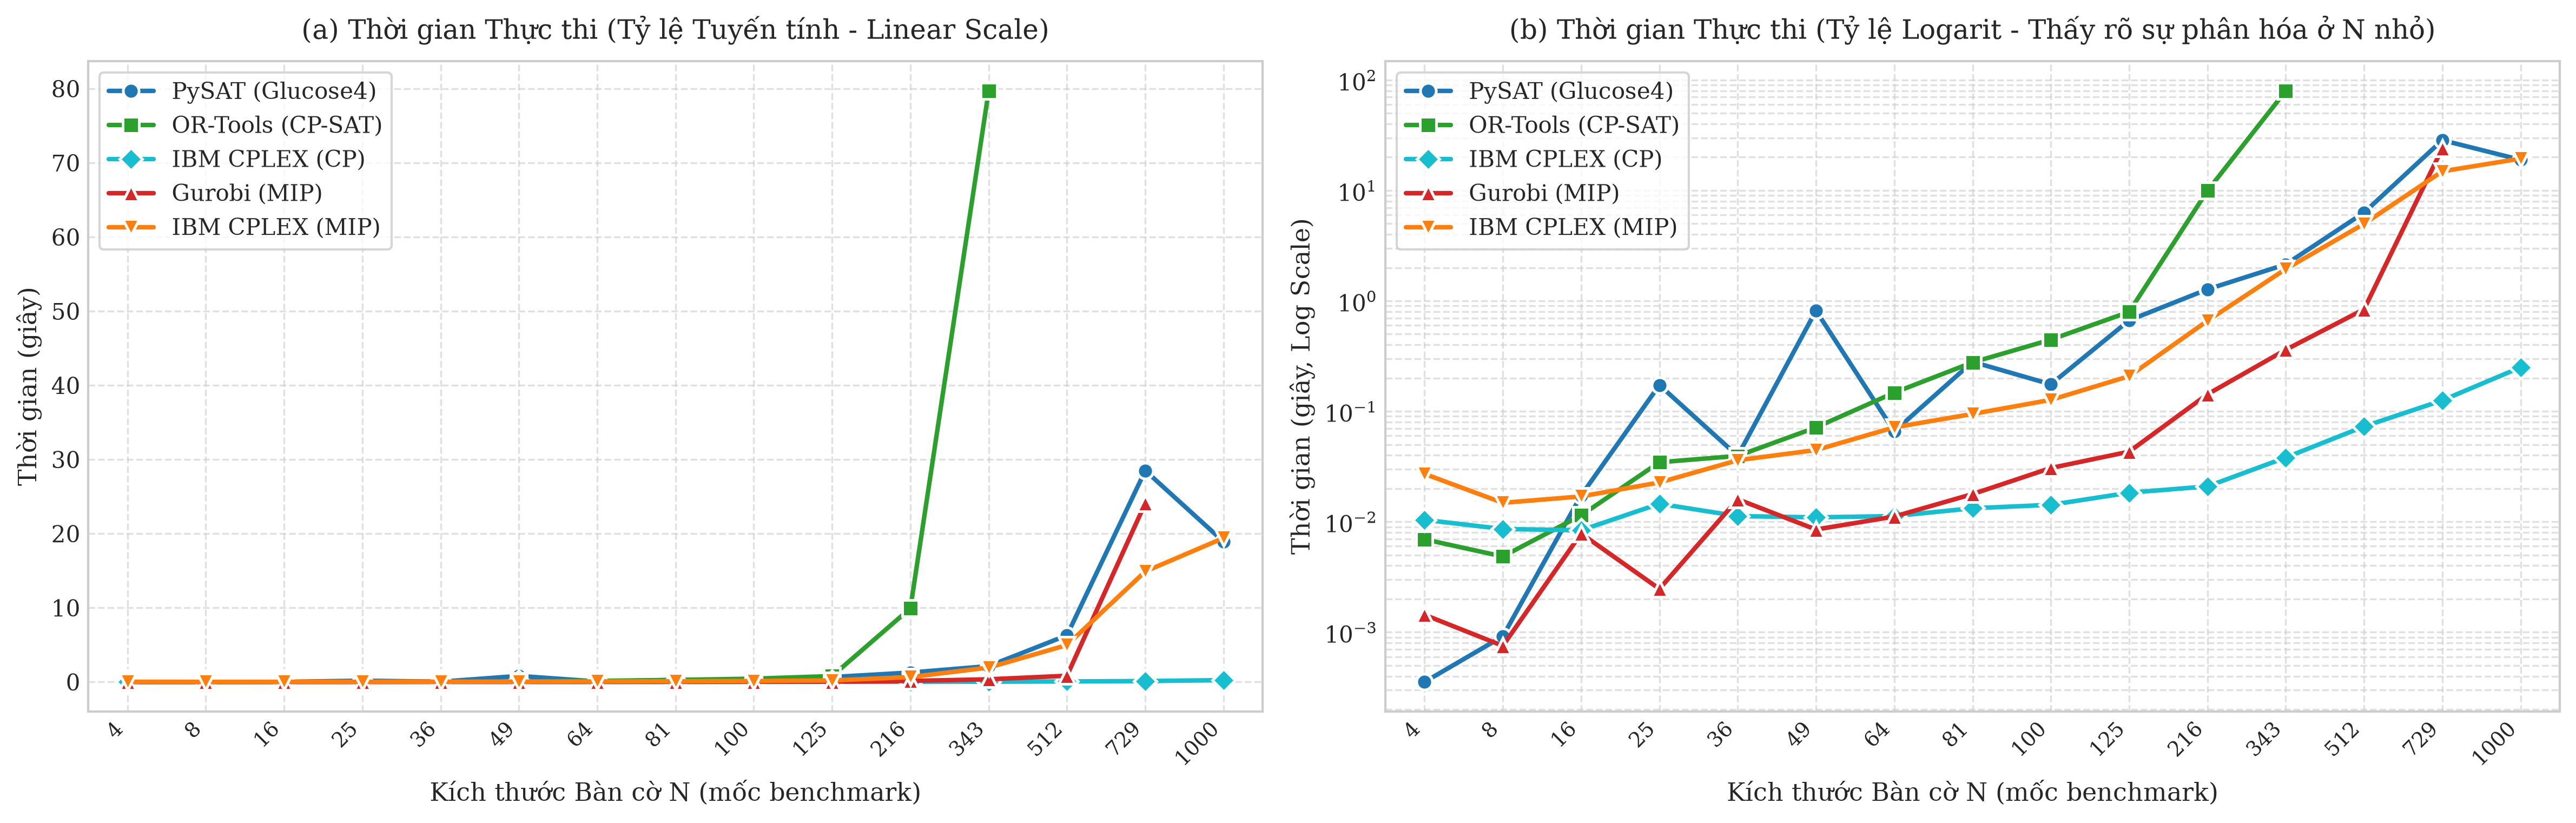

In [3]:
# 1. Bảng Pivot Thời gian Thực thi (giây)
# Lấy các trường hợp giải thành công (không timeout)
pivot_time = df[df['status'].isin(['SAT', 'OPTIMAL', 'FEASIBLE'])].pivot(index='n', columns='solver', values='time')[SOLVER_ORDER]
display(pivot_time)

# 2. Vẽ biểu đồ Thời gian Thực thi vs N (2 Subplots: Linear Scale & Log Scale)
n_list = [4, 8, 16, 25, 36, 49, 64, 81, 100, 125, 216, 343, 512, 729, 1000]
x_map = {n: i for i, n in enumerate(n_list)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))

for solver in SOLVER_ORDER:
    data_s = df[(df['solver'] == solver) & (df['status'].isin(['SAT', 'OPTIMAL', 'FEASIBLE']))].sort_values('n')
    lbl = SOLVER_LABELS.get(solver, solver)
    color = SOLVER_COLORS.get(solver, None)
    marker = SOLVER_MARKERS.get(solver, 'o')
    if not data_s.empty:
        xs = [x_map[n] for n in data_s['n']]
        # Subplot 1: Linear Scale
        ax1.plot(xs, data_s['time'], marker=marker, markersize=7, markeredgecolor='white',
                 markeredgewidth=1.2, label=lbl, color=color, linewidth=2)
        # Subplot 2: Log Scale
        ax2.plot(xs, data_s['time'], marker=marker, markersize=7, markeredgecolor='white',
                 markeredgewidth=1.2, label=lbl, color=color, linewidth=2)

# Thiết lập Subplot 1: Linear
ax1.set_title('(a) Thời gian Thực thi (Tỷ lệ Tuyến tính - Linear Scale)', fontsize=12, pad=10)
ax1.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax1.set_ylabel('Thời gian (giây)', fontsize=11)
ax1.set_xticks(range(len(n_list)))
ax1.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax1.set_xlim(-0.5, len(n_list) - 0.5)
ax1.legend(frameon=True, loc='upper left', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# Thiết lập Subplot 2: Log
ax2.set_title('(b) Thời gian Thực thi (Tỷ lệ Logarit - Thấy rõ sự phân hóa ở N nhỏ)', fontsize=12, pad=10)
ax2.set_xlabel('Kích thước Bàn cờ N (mốc benchmark)', fontsize=11)
ax2.set_ylabel('Thời gian (giây, Log Scale)', fontsize=11)
ax2.set_yscale('log')
ax2.set_xticks(range(len(n_list)))
ax2.set_xticklabels(n_list, rotation=45, ha='right', fontsize=9)
ax2.set_xlim(-0.5, len(n_list) - 0.5)
ax2.legend(frameon=True, loc='upper left', fontsize=10)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/solver_total_time.png', dpi=300, bbox_inches='tight')
plt.show()


## 2. Tóm tắt Kết luận Chính

1. **Constraint Programming (CP - IBM CPLEX CP Optimizer) - Đạt hiệu năng tối thượng:**
   - Với chỉ $N$ biến nguyên và 3 ràng buộc toàn cục `AllDifferent`, mô hình CP thể hiện sự tương thích hoàn hảo nhất cho bài toán N-Queens.
   - IBM CPLEX (CP) giải kích thước cực đại $N = 1000$ trong vỏn vẹn **0.250 giây**, hoàn toàn vượt trội so với mọi phương pháp còn lại.
2. **SAT Solving (PySAT Glucose4 với Commander Variable) - Khả năng mở rộng xuất sắc:**
   - Việc áp dụng mã hóa **Commander Variable** giúp Glucose4 giải quyết trọn vẹn bài toán đến $N = 1000$ (gần 3 triệu biến logic) trong **18.92 giây**, chứng minh sức mạnh của bộ giải SAT hiện đại khi có chiến lược mã hóa tối ưu.
3. **Mixed Integer Programming (MIP - Gurobi & IBM CPLEX MIP):**
   - Nhờ bản quyền học thuật đầy đủ, cả Gurobi và CPLEX MIP phát huy tối đa sức mạnh thuật toán Presolve và Branch-and-Cut.
   - **Gurobi** giải cực nhanh ở các bài toán trung bình - lớn: $N = 512$ trong **0.838s**, $N = 729$ trong **24.10s** (chạm timeout ở $N = 1000$).
   - **IBM CPLEX MIP** hoàn thành xuất sắc mốc $N = 1000$ (1 triệu biến nhị phân) trong **19.42 giây**.
4. **Google OR-Tools (CP-SAT):**
   - Đạt tốc độ cao ở miền $N \le 343$ (79.70s), bắt đầu chạm ngưỡng giới hạn thời gian (timeout 120s) từ $N \ge 512$ do không gian tìm kiếm CP-SAT mở rộng khi quy mô lớn.
